# 04. Modeling, Evaluation & OLS Diagnostics
**Objective:** Train and evaluate linear forecasting models on out-of-time test data (`2019–2023`) via a structured Ablation Study, benchmark against SMART objectives (`Adj. R² >= 0.80`, `RMSE <= 40`, `MAPE < 10%`), verify the 4 classical OLS assumptions, and analyze sector-level forecast errors.

### Pipeline Checklist:
- [ ] Load verified `train`/`test` feature matrices & verify metadata alignment
- [ ] Run Systematic Ablation Study (`Baseline t` → `+ Sector` → `+ Sector × t` → `+ Month`)
- [ ] Inspect OLS Summary & interpret domain coefficients (Trillion BTU)
- [ ] Validate 4 Classical OLS Assumptions (VIF, Breusch-Pagan, Durbin-Watson/BG, Jarque-Bera) + Remediation
- [ ] Visualize Out-of-Time Forecasts (`2019–2023`) & conduct Sector-Level Error Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_breusch_godfrey
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [ ]:
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')

In [4]:
PROCESSED_DIR = Path('../data/processed')
FIGURES_DIR = Path('../reports/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [6]:
X_train = pd.read_csv(PROCESSED_DIR / "X_train.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test.csv")
X_train_scaled = pd.read_csv(PROCESSED_DIR / "X_train_scaled.csv")
X_test_scaled = pd.read_csv(PROCESSED_DIR / "X_test_scaled.csv")

y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv")["Total Renewable Energy"]
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv")["Total Renewable Energy"]

df_clean = pd.read_csv(PROCESSED_DIR / "renewable_clean.csv")
meta_train = df_clean[df_clean["Year"] <= 2018][
    ["Year", "Month", "Sector", "Total Renewable Energy"]
].reset_index(drop=True)
meta_test = df_clean[df_clean["Year"] > 2018][
    ["Year", "Month", "Sector", "Total Renewable Energy"]
].reset_index(drop=True)

In [ ]:
assert X_train.shape[0] == len(y_train) == len(meta_train), "Train row alignment mismatch!"
assert X_test.shape[0] == len(y_test) == len(meta_test), "Test row alignment mismatch!"
assert np.allclose(meta_train['Total Renewable Energy'], y_train), "y_train ordering mismatch!"
assert np.allclose(meta_test['Total Renewable Energy'], y_test), "y_test ordering mismatch!"

print(f"Loaded Train: X={X_train.shape}, y={y_train.shape} ({meta_train['Year'].min()}–{meta_train['Year'].max()})")
print(f"Loaded Test : X={X_test.shape},  y={y_test.shape}  ({meta_test['Year'].min()}–{meta_test['Year'].max()})")
print(f"Target min -> Train: {y_train.min():.3f} | Test: {y_test.min():.3f} Trillion BTU (zero-check for MAPE)")

Loaded Train: X=(2208, 18), y=(2208,) (1973–2018)
Loaded Test : X=(240, 18),  y=(240,)  (2019–2023)
Target min -> Train: 0.515 | Test: 16.013 Trillion BTU (zero-check for MAPE)


### 2. Systematic Ablation Study (`Model 1` → `Model 4`)
**Objective:** Progressively evaluate each engineered feature group on unseen out-of-time data (`2019–2023`) and benchmark performance against our SMART targets (`Test Adj. R² >= 0.80`, `Test RMSE <= 40 Trillion BTU`, `Test MAPE < 10%`).

In [8]:
def calc_metrics(y_true, y_pred, p):
    r2 = r2_score(y_true,y_pred)
    adj_r2 = 1 - (1 - r2) * (len(y_true) - 1) / (len(y_true) - p - 1)
    rmse = np.sqrt(mean_squared_error(y_true,y_pred))
    mae = mean_absolute_error(y_true,y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return r2, adj_r2, rmse, mae, mape

In [9]:
sector_cols = ['Sector_Electric Power', 'Sector_Industrial', 'Sector_Residential']
interaction_cols = ['Sector_Electric Power_x_t', 'Sector_Industrial_x_t', 'Sector_Residential_x_t']
month_cols = [f'Month_{m}' for m in range(2, 13)]

feature_sets = {
    'Model 1: Baseline (t)': ['t'],
    'Model 2: + Sector': ['t'] + sector_cols,
    'Model 3: + Sector x t': ['t'] + sector_cols + interaction_cols,
    'Model 4: + Month (Full)': ['t'] + sector_cols + interaction_cols + month_cols,
}


In [13]:
results = []
fitted_models = {}

for name, cols in feature_sets.items():
    model = LinearRegression()
    model.fit(X_train[cols], y_train)
    fitted_models[name] = model
    prediction = model.predict(X_train[cols])
    tr_r2, tr_adj_r2, tr_rmse, tr_mae, tr_mape = calc_metrics(
        y_train, prediction, len(cols)
    )
    te_r2, te_adj_r2, te_rmse, te_mae, te_mape = calc_metrics(
        y_test, model.predict(X_test[cols]), len(cols)
    )
    results.append(
        {
            "Model": name,
            "Features (p)": len(cols),
            "Train Adj. R²": round(tr_adj_r2, 4),
            "Test R²": round(te_r2, 4),
            "Test Adj. R²": round(te_adj_r2, 4),
            "Test RMSE": round(te_rmse, 2),
            "Test MAE": round(te_mae, 2),
            "Test MAPE (%)": round(te_mape, 2),
            "SMART R² (>=0.80)": te_adj_r2 >= 0.80,
            "SMART RMSE (<=40)": te_rmse <= 40.0,
        }
    )
ablation_df = pd.DataFrame(results)
display(ablation_df)

,Model,Features (p),Train Adj. R²,Test R²,Test Adj. R²,Test RMSE,Test MAE,Test MAPE (%),SMART R² (>=0.80),SMART RMSE (<=40)
0,Model 1: Baseline (t),1,0.0570,-0.0282,-0.0325,98.54,93.22,172.09,False,False
1,Model 2: + Sector,4,0.8752,0.6653,0.6596,56.22,40.26,47.81,False,False
2,Model 3: + Sector x t,7,0.9324,0.8524,0.8479,37.34,23.35,15.83,True,True
3,Model 4: + Month (Full),18,0.9342,0.8544,0.8426,37.08,23.35,16.60,True,True


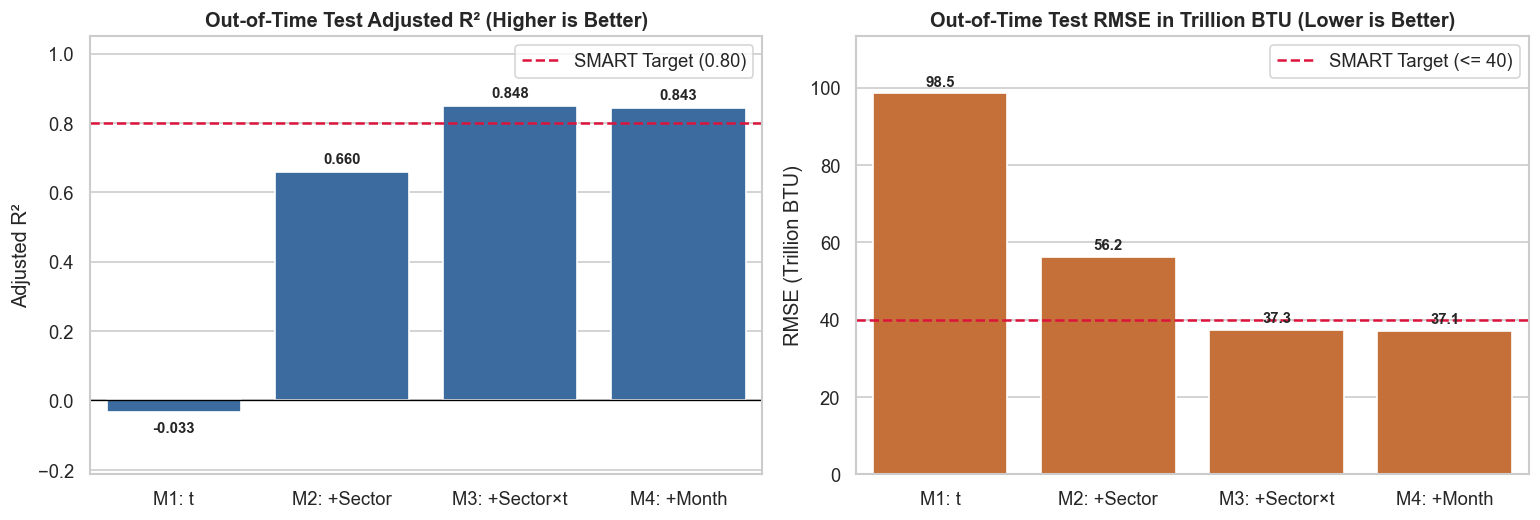

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
short_labels = ['M1: t', 'M2: +Sector', 'M3: +Sector×t', 'M4: +Month']
sns.barplot(x=short_labels, y=ablation_df['Test Adj. R²'], ax=axes[0], color='#2b6cb0')
axes[0].axhline(0.80, color='crimson', linestyle='--', linewidth=1.5, label='SMART Target (0.80)')
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_ylim(min(ablation_df['Test Adj. R²'].min() - 0.18, -0.05), 1.05)
axes[0].set_title('Out-of-Time Test Adjusted R² (Higher is Better)', fontweight='bold')
axes[0].set_ylabel('Adjusted R²')
axes[0].legend()
sns.barplot(x=short_labels, y=ablation_df['Test RMSE'], ax=axes[1], color='#dd6b20')
axes[1].axhline(40.0, color='crimson', linestyle='--', linewidth=1.5, label='SMART Target (<= 40)')
axes[1].set_ylim(0, ablation_df['Test RMSE'].max() * 1.15)
axes[1].set_title('Out-of-Time Test RMSE in Trillion BTU (Lower is Better)', fontweight='bold')
axes[1].set_ylabel('RMSE (Trillion BTU)')
axes[1].legend()
for i, v in enumerate(ablation_df['Test Adj. R²']):
    axes[0].text(i, v + (0.025 if v >= 0 else -0.06), f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')
for i, v in enumerate(ablation_df['Test RMSE']):
    axes[1].text(i, v + ablation_df['Test RMSE'].max() * 0.02, f'{v:.1f}', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_ablation_study.png', dpi=150, bbox_inches='tight')
plt.show()

### 3. OLS Statistical Inference & Domain Coefficient Interpretation
**Objective:** Fit the full feature specification (`Model 4`) using `statsmodels.OLS` to inspect feature-level statistical significance (`p-values`), overall F-statistic, and translate interaction slopes into sector-level annual growth rates (`Trillion BTU / year`).

In [17]:
X_train_const = sm.add_constant(X_train, has_constant='add')
X_test_const = sm.add_constant(X_test, has_constant='add')

ols_model = sm.OLS(y_train, X_train_const).fit()
print(ols_model.summary())


                              OLS Regression Results                              
Dep. Variable:     Total Renewable Energy   R-squared:                       0.935
Model:                                OLS   Adj. R-squared:                  0.934
Method:                     Least Squares   F-statistic:                     1742.
Date:                    Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                            20:48:52   Log-Likelihood:                -9287.1
No. Observations:                    2208   AIC:                         1.861e+04
Df Residuals:                        2189   BIC:                         1.872e+04
Df Model:                              18                                         
Covariance Type:                nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------

In [19]:
params = ols_model.params
pvals = ols_model.pvalues

sector_growth = pd.DataFrame([
    {'Sector': 'Commercial (Baseline)', 'Monthly Slope (BTU/mo)': params['t'], 'Annual Growth (BTU/yr)': params['t'] * 12},
    {'Sector': 'Electric Power', 'Monthly Slope (BTU/mo)': params['t'] + params['Sector_Electric Power_x_t'], 'Annual Growth (BTU/yr)': (params['t'] + params['Sector_Electric Power_x_t']) * 12},
    {'Sector': 'Industrial', 'Monthly Slope (BTU/mo)': params['t'] + params['Sector_Industrial_x_t'], 'Annual Growth (BTU/yr)': (params['t'] + params['Sector_Industrial_x_t']) * 12},
    {'Sector': 'Residential', 'Monthly Slope (BTU/mo)': params['t'] + params['Sector_Residential_x_t'], 'Annual Growth (BTU/yr)': (params['t'] + params['Sector_Residential_x_t']) * 12},
])

print("\nImplied Linear Growth Trajectory by Sector (1973–2018 Training Fit):")
display(sector_growth.round(4))
non_sig = pvals[pvals >= 0.05]
print(f"\nNon-significant features (p >= 0.05): {list(non_sig.index)}")




Implied Linear Growth Trajectory by Sector (1973–2018 Training Fit):


,Sector,Monthly Slope (BTU/mo),Annual Growth (BTU/yr)
0,Commercial (Baseline),4.7662,57.1941
1,Electric Power,30.7470,368.9639
2,Industrial,24.0570,288.6835
3,Residential,-2.7859,-33.4310



Non-significant features (p >= 0.05): ['Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_12']
